# Laboratorio #4 — Análisis Exploratorio de Datos (EDA)
**Universidad Técnica Nacional · ISW-911 Minería de Datos**

**Integrantes del grupo:**
- Krisley Castro Barrantes
- ______________________
- ______________________
- ______________________

**Conjunto de datos:** *Precios medios de electricidad* — Autoridad Reguladora de los Servicios Públicos (ARESEP), datos abiertos, enero 2025 a agosto 2026.

Cada fila es la facturación de **una empresa eléctrica**, en **una tarifa**, durante **un mes**: cantidad de abonados, energía vendida (kWh), ingresos (₡) y precio medio (₡/kWh), con y sin el Costo Variable de Generación (CVG).

## 0. Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

---
# Parte 1 (puntos 2, 3, 4, 5 y 15)

## Puntos 2 y 3. Carga del conjunto de datos desde Git
El conjunto de datos de ARESEP viene en dos archivos (2025 y 2026) con las mismas columnas. Los dos se subieron sin modificar a la carpeta `data/` del repositorio público de GitHub del grupo y se leen directamente desde la URL *raw* de GitHub.

> Si GitHub no responde, el notebook usa la copia local de `data/` para poder seguir trabajando. **Para la entrega la lectura tiene que salir desde Git.**

In [2]:
# >>> Cambiar USUARIO y REPOSITORIO por los del grupo (el repo debe ser público o compartido con utn-frocha) <<<
URL_BASE_GIT = "https://raw.githubusercontent.com/USUARIO/REPOSITORIO/main/data/"

ARCHIVOS = [
    "Datos_Abiertos_ARESEP_Precios_medios_2025.csv",
    "Datos_Abiertos_ARESEP_Precios_medios_2026.csv",
]

def leer_csv_git(nombre_archivo):
    """Lee un CSV desde el repositorio de GitHub; si falla, usa la copia local en data/."""
    try:
        datos = pd.read_csv(URL_BASE_GIT + nombre_archivo, encoding="utf-8")
        print(f"Leído desde GitHub: {nombre_archivo}")
    except Exception as error:
        datos = pd.read_csv("data/" + nombre_archivo, encoding="utf-8")
        print(f"GitHub no disponible ({type(error).__name__}); leído desde la copia local: {nombre_archivo}")
    return datos

df = pd.concat([leer_csv_git(archivo) for archivo in ARCHIVOS], ignore_index=True)
print("Filas y columnas del conjunto unido:", df.shape)

GitHub no disponible (HTTPError); leído desde la copia local: Datos_Abiertos_ARESEP_Precios_medios_2025.csv
GitHub no disponible (HTTPError); leído desde la copia local: Datos_Abiertos_ARESEP_Precios_medios_2026.csv
Filas y columnas del conjunto unido: (1472, 13)


## Punto 4. Funciones básicas para ver las características del conjunto de datos

### 4.1 Primeras y últimas filas

In [3]:
df.head(10)

,Mes,Año,Empresa,Tarifa,Abonados,Ventas,Ingreso sin CVG,Ingreso con CVG,Precio Medio sin CVG,Precio Medio con CVG,Trimestre,Sistema,Trimestral
0,Diciembre,2025,CNFL,Alumbrado Público,0,"5,221,777.24","192,784,383.98","192,784,383.98",36.92,36.92,IV Trimestre,Distribucion,2025 4
1,Diciembre,2025,COOPESANTOS,Residencial,49685,"7,043,995.00","579,458,200.00","641,552,600.00",82.26,91.08,IV Trimestre,Distribucion,2025 4
2,Diciembre,2025,COOPELESCA,Residencial,108073,"19,937,840.00","1,546,824,000.00","1,633,719,000.00",77.58,81.94,IV Trimestre,Distribucion,2025 4
3,Diciembre,2025,COOPEGUANACASTE,Residencial,82147,"26,467,370.00","1,863,072,000.00","2,180,751,000.00",70.39,82.39,IV Trimestre,Distribucion,2025 4
4,Diciembre,2025,COOPEALFARORUIZ,Residencial,6356,"1,543,944.00","83,966,910.00","106,147,200.00",54.38,68.75,IV Trimestre,Distribucion,2025 4
5,Diciembre,2025,CNFL,Residencial,539680,"130,242,900.00","8,301,342,000.00","10,632,540,000.00",63.74,81.64,IV Trimestre,Distribucion,2025 4
6,Diciembre,2025,TOTAL NACIONAL,Promocional,30,"539,153.00","36,758,295.00","47,081,765.00",68.18,87.33,IV Trimestre,Distribucion,2025 4
7,Diciembre,2025,ESPH,Residencial,85454,"22,693,980.00","1,535,907,000.00","1,861,652,000.00",67.68,82.03,IV Trimestre,Distribucion,2025 4
8,Diciembre,2025,CNFL,Promocional,30,"539,153.00","36,758,295.00","47,081,765.00",68.18,87.33,IV Trimestre,Distribucion,2025 4
9,Diciembre,2025,JASEC,Preferencial,688,"884,066.00","43,117,180.00","53,931,760.00",48.77,61.00,IV Trimestre,Distribucion,2025 4


In [4]:
df.tail(5)

,Mes,Año,Empresa,Tarifa,Abonados,Ventas,Ingreso sin CVG,Ingreso con CVG,Precio Medio sin CVG,Precio Medio con CVG,Trimestre,Sistema,Trimestral
1467,Enero,2026,COOPESANTOS,Industrial,199,"283,396.17","45,076,160.00","44,279,380.00",159.06,156.25,I Trimestre,Distribucion,2026 1
1468,Enero,2026,COOPELESCA,Industrial,1671,"4,007,982.07","371,932,500.00","378,030,000.00",92.80,94.32,I Trimestre,Distribucion,2026 1
1469,Enero,2026,COOPEGUANACASTE,Industrial,231,"1,341,862.71","125,578,272.00","139,582,377.00",93.59,104.02,I Trimestre,Distribucion,2026 1
1470,Enero,2026,CNFL,Industrial,1354,"4,582,995.00","465,948,420.00","531,556,600.00",101.67,115.98,I Trimestre,Distribucion,2026 1
1471,Enero,2026,TOTAL NACIONAL,Ventas al servicio de Distribución,0,"116,932,677.00","4,754,417,406.91","4,524,353,066.38",40.66,38.69,I Trimestre,Generacion,2026 1


### 4.2 Tamaño, columnas y tipos de datos

In [5]:
print("Cantidad de filas:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])
print("\nColumnas:", list(df.columns))
print("\nTipos de datos:")
print(df.dtypes)

Cantidad de filas: 1472
Cantidad de columnas: 13

Columnas: ['Mes', 'Año', 'Empresa', 'Tarifa', 'Abonados', 'Ventas', 'Ingreso sin CVG', 'Ingreso con CVG', 'Precio Medio sin CVG', 'Precio Medio con CVG', 'Trimestre', 'Sistema', 'Trimestral']

Tipos de datos:
Mes                         str
Año                       int64
Empresa                     str
Tarifa                      str
Abonados                  int64
Ventas                  float64
Ingreso sin CVG         float64
Ingreso con CVG         float64
Precio Medio sin CVG    float64
Precio Medio con CVG    float64
Trimestre                   str
Sistema                     str
Trimestral                  str
dtype: object


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1472 entries, 0 to 1471
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Mes                   1472 non-null   str    
 1   Año                   1472 non-null   int64  
 2   Empresa               1472 non-null   str    
 3   Tarifa                1472 non-null   str    
 4   Abonados              1472 non-null   int64  
 5   Ventas                1472 non-null   float64
 6   Ingreso sin CVG       1472 non-null   float64
 7   Ingreso con CVG       1472 non-null   float64
 8   Precio Medio sin CVG  1472 non-null   float64
 9   Precio Medio con CVG  1472 non-null   float64
 10  Trimestre             1472 non-null   str    
 11  Sistema               1472 non-null   str    
 12  Trimestral            1472 non-null   str    
dtypes: float64(5), int64(2), str(6)
memory usage: 149.6 KB


### 4.3 Estadísticas descriptivas de las variables numéricas

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Año,"1,472.00","2,025.40",0.49,"2,025.00","2,025.00","2,025.00","2,026.00","2,026.00"
Abonados,"1,472.00","55,917.96","231,847.30",0.00,0.00,221.50,"7,298.50","1,790,412.00"
Ventas,"1,472.00","50,915,257.94","119,047,459.53",0.00,"964,452.50","8,314,585.00","30,764,530.06","833,571,960.58"
Ingreso sin CVG,"1,472.00","2,734,801,683.28","5,753,772,423.02","-115,904,929.23","57,625,415.00","568,918,550.00","1,766,096,182.50","33,530,904,080.00"
Ingreso con CVG,"1,472.00","3,219,984,503.47","6,780,650,483.82",45.02,"67,230,900.12","619,034,399.02","2,023,926,083.10","36,205,987,336.47"
Precio Medio sin CVG,"1,472.00","172,287.71","3,852,414.21",-236.77,49.26,64.68,81.96,"124,181,785.01"
Precio Medio con CVG,"1,472.00","168,912.05","3,655,600.32",0.00,54.05,72.66,87.13,"116,269,992.45"


### 4.4 Resumen de las variables categóricas (texto)

In [8]:
df.describe(exclude='number').T

,count,unique,top,freq
Mes,1472,12,Agosto,148
Empresa,1472,10,TOTAL NACIONAL,236
Tarifa,1472,13,Alumbrado Público,180
Trimestre,1472,4,II Trimestre,442
Sistema,1472,2,Distribucion,1252
Trimestral,1472,7,2025 4,222


In [9]:
# Cantidad de valores distintos por columna
df.nunique().sort_values()

Año                        2
Sistema                    2
Trimestre                  4
Trimestral                 7
Empresa                   10
Mes                       12
Tarifa                    13
Abonados                 684
Precio Medio con CVG    1161
Precio Medio sin CVG    1178
Ventas                  1380
Ingreso sin CVG         1390
Ingreso con CVG         1390
dtype: int64

In [10]:
# Frecuencias de las principales variables categóricas
for columna in ["Empresa", "Tarifa", "Sistema", "Trimestre"]:
    print(f"--- {columna} ---")
    print(df[columna].value_counts(), "\n")

--- Empresa ---
Empresa
TOTAL NACIONAL       236
CNFL                 200
ESPH                 180
ICE                  180
JASEC                160
COOPELESCA           156
COOPESANTOS          140
COOPEGUANACASTE      100
COOPEALFARORUIZ      100
Usuarios Directos     20
Name: count, dtype: int64 

--- Tarifa ---
Tarifa
Alumbrado Público                        180
Residencial                              180
Comercios y servicios                    180
Industrial                               180
Ventas al servicio de Distribución       140
Media tensión a                          140
Preferencial                             120
Media tensión b                          120
Residencial horaria                       80
Ventas a ICE distribución y a la CNFL     60
Promocional                               40
Residencial modalidad prepago             32
Usuarios Directos                         20
Name: count, dtype: int64 

--- Sistema ---
Sistema
Distribucion    1252
Generacion       2

In [11]:
print("Filas duplicadas:", df.duplicated().sum())
print("Memoria usada: {:.1f} KB".format(df.memory_usage(deep=True).sum() / 1024))

Filas duplicadas: 0
Memoria usada: 623.0 KB


### 4.5 Vista gráfica rápida

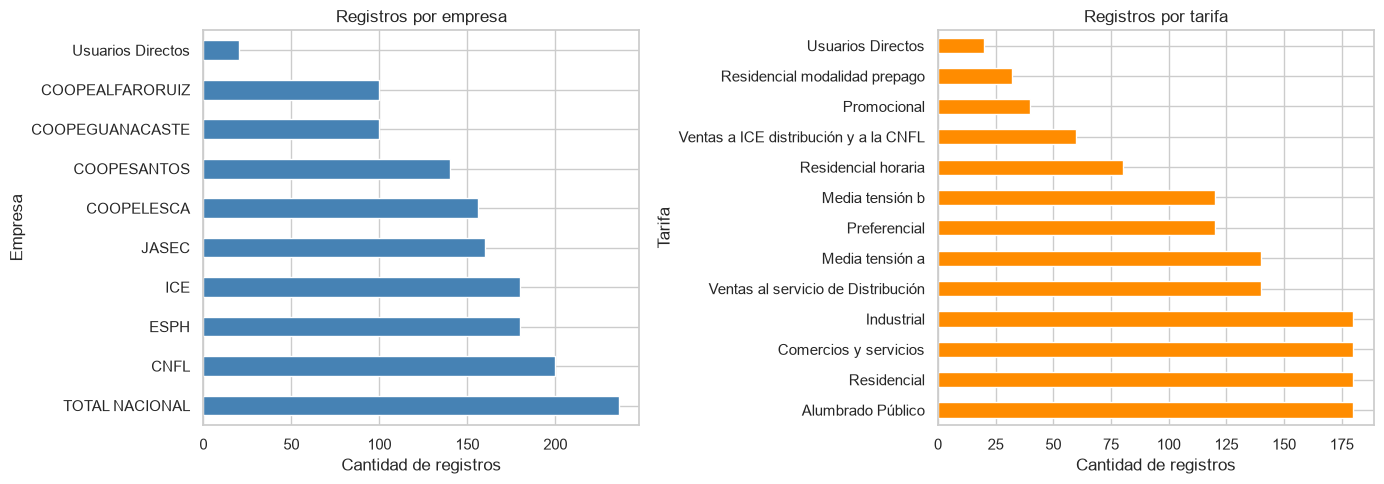

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
df["Empresa"].value_counts().plot(kind="barh", ax=ejes[0], color="steelblue")
ejes[0].set_title("Registros por empresa")
ejes[0].set_xlabel("Cantidad de registros")
df["Tarifa"].value_counts().plot(kind="barh", ax=ejes[1], color="darkorange")
ejes[1].set_title("Registros por tarifa")
ejes[1].set_xlabel("Cantidad de registros")
plt.tight_layout()
plt.show()

**Observaciones:**
- El conjunto tiene 1 472 filas y 13 columnas: 7 numéricas y 6 de texto.
- Hay 10 "empresas", pero una de ellas es **TOTAL NACIONAL**. No es una empresa, es la suma de las demás, así que sus filas repiten información (se revisa en valores atípicos).
- `Sistema` separa la **Distribución** (venta al cliente final) de la **Generación** (venta entre empresas).
- La columna `Mes` trae espacios en blanco al final (`"Julio     "`), lo cual hay que limpiar.

## Punto 5. Cambio de nombres de las columnas a español
Los nombres originales mezclan mayúsculas, espacios, tildes, la letra ñ (`Año`) y siglas (`CVG`). Se cambian a nombres en español **descriptivos**, en minúscula, sin espacios ni tildes, y con la unidad cuando aplica. Así son más fáciles de usar en código.

In [13]:
nombres_columnas = {
    "Mes": "mes",
    "Año": "anio",
    "Empresa": "empresa",
    "Tarifa": "tarifa",
    "Abonados": "cantidad_abonados",
    "Ventas": "ventas_kwh",
    "Ingreso sin CVG": "ingreso_sin_cvg_colones",
    "Ingreso con CVG": "ingreso_con_cvg_colones",
    "Precio Medio sin CVG": "precio_medio_sin_cvg",
    "Precio Medio con CVG": "precio_medio_con_cvg",
    "Trimestre": "trimestre",
    "Sistema": "sistema",
    "Trimestral": "periodo_trimestral",
}
df = df.rename(columns=nombres_columnas)
df.columns.tolist()

['mes',
 'anio',
 'empresa',
 'tarifa',
 'cantidad_abonados',
 'ventas_kwh',
 'ingreso_sin_cvg_colones',
 'ingreso_con_cvg_colones',
 'precio_medio_sin_cvg',
 'precio_medio_con_cvg',
 'trimestre',
 'sistema',
 'periodo_trimestral']

| Columna nueva | Significado |
|---|---|
| `mes`, `anio` | Mes y año del registro |
| `empresa` | Empresa eléctrica (ICE, CNFL, JASEC, ESPH, cooperativas…) |
| `tarifa` | Tipo de tarifa (residencial, preferencial, alumbrado público…) |
| `cantidad_abonados` | Número de clientes (abonados) en esa tarifa |
| `ventas_kwh` | Energía vendida en el mes (kWh) |
| `ingreso_sin_cvg_colones` / `ingreso_con_cvg_colones` | Ingreso facturado (₡) sin / con el Costo Variable de Generación |
| `precio_medio_sin_cvg` / `precio_medio_con_cvg` | Precio medio (₡/kWh) = ingreso ÷ ventas |
| `trimestre`, `periodo_trimestral` | Trimestre del año |
| `sistema` | Distribución o Generación |